# Marketing Campaign Performance Analysis

Which channels earn their budget, where does spend stop paying off, and where should the next dollar go?

**About the data.** `marketing_campaigns.csv` holds 480 campaigns across 5 channels for 2025. It is **synthetic** (generated by `generate_data.py` with a fixed seed), so the findings describe this dataset, not any real company.

**Questions**
1. Which channel returns the most revenue per dollar spent?
2. Where does each channel's funnel (impressions, clicks, conversions) leak?
3. How do spend and return change through the year?
4. Does spending more on a campaign keep paying off?
5. If budget moves between channels, what changes?

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 4.5)

df = pd.read_csv("marketing_campaigns.csv")
df.head()

,campaign_id,month,channel,spend,impressions,clicks,conversions,revenue
0,C0001,2025-01,Google Search,1125.83,15658,966,34,2910.93
1,C0002,2025-01,Google Search,2514.09,31124,1991,80,6081.59
2,C0003,2025-01,Google Search,1105.43,14209,985,41,2993.29
3,C0004,2025-01,Google Search,1323.85,18317,1120,43,3705.04
4,C0005,2025-01,Google Search,449.19,5352,356,12,925.80


## Data cleaning

In [2]:
print(df.shape)
print("missing values:", int(df.isna().sum().sum()))
print("duplicate campaigns:", int(df.campaign_id.duplicated().sum()))
print("rows with zero clicks or zero spend:", int(((df.clicks == 0) | (df.spend == 0)).sum()))
df.describe().round(1)

(480, 8)
missing values: 0
duplicate campaigns: 0
rows with zero clicks or zero spend: 0


,spend,impressions,clicks,conversions,revenue
count,480.0,480.0,480.0,480.0,480.0
mean,897.5,42359.8,855.4,26.0,2294.1
std,650.4,43651.6,740.5,22.6,1927.9
min,81.7,3006.0,56.0,0.0,0.0
25%,451.5,16014.8,371.5,10.0,998.7
50%,738.1,28984.5,664.0,19.0,1708.0
75%,1141.0,50345.5,1093.5,36.0,3039.3
max,4569.4,282973.0,4803.0,143.0,13275.2


## Metrics used
Ratios are computed from **summed** totals, never by averaging per-campaign ratios, so large campaigns carry the weight they should.

- CTR = clicks / impressions
- CVR = conversions / clicks
- CPA = spend / conversions
- ROAS = revenue / spend

In [3]:
def metrics(g):
    return pd.Series({
        "spend": g.spend.sum(), "revenue": g.revenue.sum(),
        "ctr_%": 100 * g.clicks.sum() / g.impressions.sum(),
        "cvr_%": 100 * g.conversions.sum() / g.clicks.sum(),
        "cpa": g.spend.sum() / g.conversions.sum(),
        "roas": g.revenue.sum() / g.spend.sum(),
    })

by_channel = df.groupby("channel").apply(metrics, include_groups=False).sort_values("roas", ascending=False)
by_channel.round(2)

,spend,revenue,ctr_%,cvr_%,cpa,roas
channel,,,,,,
Email,39784.90,300378.71,2.96,4.93,11.87,7.55
Google Search,113137.33,374272.10,6.09,4.61,25.87,3.31
Facebook Ads,92412.49,184956.34,1.76,2.05,34.53,2.00
LinkedIn,102444.53,152374.78,0.81,2.96,151.32,1.49
Instagram,83023.78,89196.44,1.52,1.50,58.63,1.07


## 1. Which channel returns the most revenue per dollar?

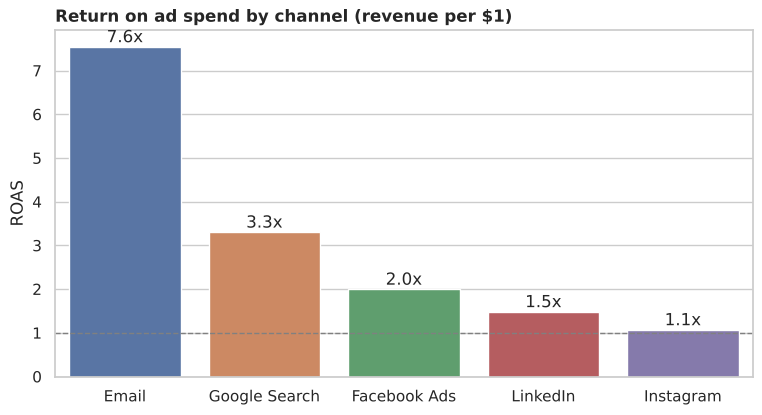

In [4]:
fig, ax = plt.subplots()
sns.barplot(x=by_channel.index, y=by_channel.roas, ax=ax, hue=by_channel.index, legend=False)
for i, v in enumerate(by_channel.roas):
    ax.text(i, v + 0.1, f"{v:.1f}x", ha="center")
ax.axhline(1, color="gray", ls="--", lw=1)
ax.set_title("Return on ad spend by channel (revenue per $1)", loc="left", fontweight="bold")
ax.set_xlabel(""); ax.set_ylabel("ROAS")
plt.show()

## 2. Where does each channel's funnel leak?

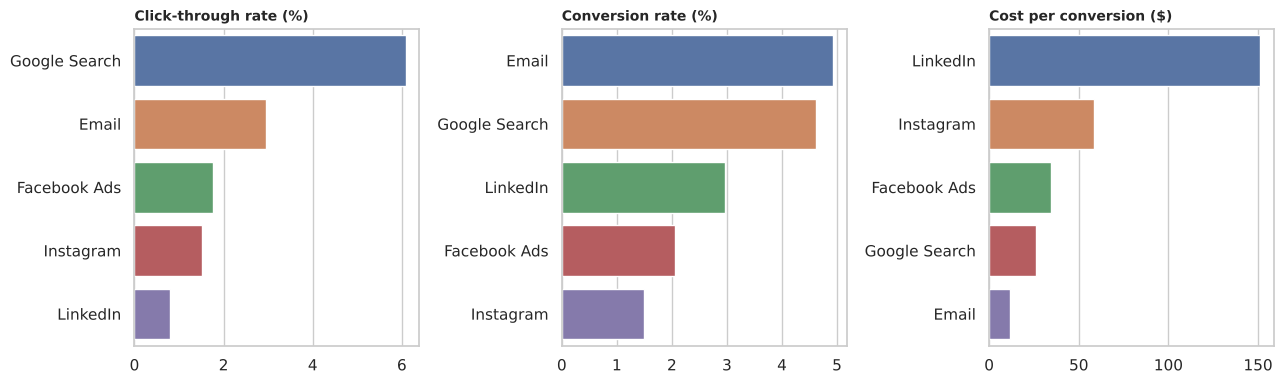

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col, title in zip(axes, ["ctr_%", "cvr_%", "cpa"], ["Click-through rate (%)", "Conversion rate (%)", "Cost per conversion ($)"]):
    d = by_channel[col].sort_values(ascending=False)
    sns.barplot(x=d.values, y=d.index, ax=ax, hue=d.index, legend=False)
    ax.set_title(title, loc="left", fontweight="bold", fontsize=10); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

## 3. How do spend and return change through the year?

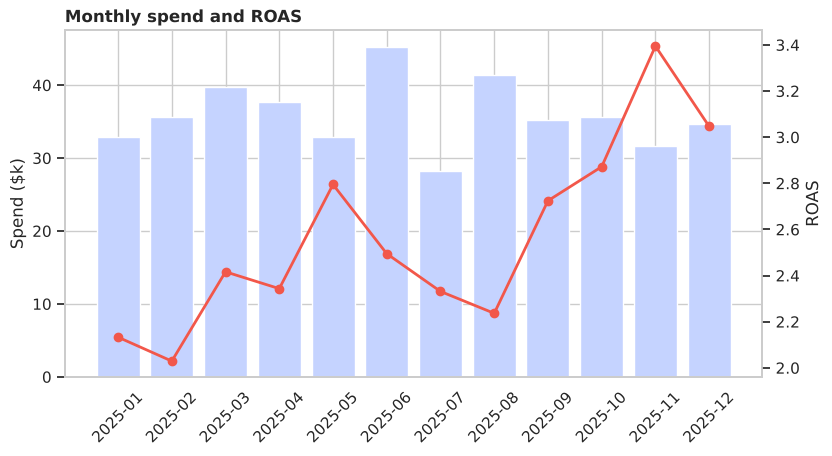

best month by ROAS : 2025-11 3.39
worst month by ROAS: 2025-02 2.03


In [6]:
monthly = df.groupby("month").apply(metrics, include_groups=False)
fig, ax1 = plt.subplots()
ax1.bar(monthly.index, monthly.spend / 1000, color="#C5D3FF", label="Spend ($k)")
ax1.set_ylabel("Spend ($k)")
ax2 = ax1.twinx(); ax2.grid(False)
ax2.plot(monthly.index, monthly.roas, color="#F2574A", marker="o", lw=2, label="ROAS")
ax2.set_ylabel("ROAS")
ax1.set_title("Monthly spend and ROAS", loc="left", fontweight="bold")
ax1.tick_params(axis="x", rotation=45)
plt.show()
print("best month by ROAS :", monthly.roas.idxmax(), round(monthly.roas.max(), 2))
print("worst month by ROAS:", monthly.roas.idxmin(), round(monthly.roas.min(), 2))

## 4. Does spending more on a campaign keep paying off?
Within each channel, campaigns are split into spend quartiles (Q1 smallest, Q4 largest) and conversion rate is compared.

                cvr_%  roas
spend_quartile             
Q1               3.60  2.97
Q2               3.25  2.69
Q3               2.97  2.39
Q4               2.88  2.50


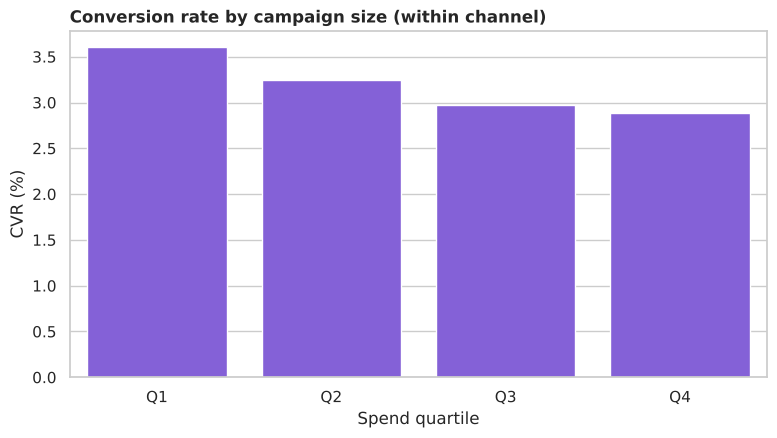

In [7]:
df["spend_quartile"] = df.groupby("channel").spend.transform(lambda s: pd.qcut(s, 4, labels=["Q1", "Q2", "Q3", "Q4"]))
q = df.groupby("spend_quartile", observed=True).apply(lambda g: pd.Series({
    "cvr_%": 100 * g.conversions.sum() / g.clicks.sum(),
    "roas": g.revenue.sum() / g.spend.sum()}), include_groups=False)
print(q.round(2))

fig, ax = plt.subplots()
sns.barplot(x=q.index, y=q["cvr_%"], ax=ax, color="#7C4DEB")
ax.set_title("Conversion rate by campaign size (within channel)", loc="left", fontweight="bold")
ax.set_xlabel("Spend quartile"); ax.set_ylabel("CVR (%)")
plt.show()

In [8]:
# Same question as a regression: log(conversion rate) against log(spend), with channel effects
import numpy as np
d = df[df.clicks > 0].copy()
d["cvr"] = d.conversions / d.clicks
d = d[d.cvr > 0]
X = pd.get_dummies(d.channel, drop_first=True).astype(float)
X["log_spend"] = np.log(d.spend)
X.insert(0, "const", 1.0)
beta, *_ = np.linalg.lstsq(X.values, np.log(d.cvr).values, rcond=None)
print("elasticity of conversion rate to spend:", round(beta[list(X.columns).index("log_spend")], 3))
print("(a value of -0.10 means doubling a campaign's spend lowers its conversion rate by about 7%)")

elasticity of conversion rate to spend: -0.094
(a value of -0.10 means doubling a campaign's spend lowers its conversion rate by about 7%)


## 5. If budget moves between channels, what changes?
Scenario: move 20% of the lowest-ROAS channel's budget to the highest-ROAS channel that is big enough to absorb it (at least 5x the amount moved, so the extra spend is a modest increase, not an extrapolation).

Section 4 showed returns shrink as spend grows, so each channel's revenue is scaled by (new spend / old spend) raised to 1 + elasticity, not by a flat ROAS. This is an estimate from synthetic data, not a forecast.

In [9]:
elasticity = beta[list(X.columns).index("log_spend")]
lo = by_channel.roas.idxmin()
moved = 0.20 * by_channel.loc[lo, "spend"]
eligible = by_channel[by_channel.spend >= 5 * moved]
hi = eligible.roas.idxmax()

def new_revenue(ch, delta):
    s0, r0 = by_channel.loc[ch, "spend"], by_channel.loc[ch, "revenue"]
    return r0 * ((s0 + delta) / s0) ** (1 + elasticity)

change = (new_revenue(lo, -moved) - by_channel.loc[lo, "revenue"]) + (new_revenue(hi, moved) - by_channel.loc[hi, "revenue"])
print(f"move ${moved:,.0f} from {lo} (ROAS {by_channel.loc[lo,'roas']:.2f}) to {hi} (ROAS {by_channel.loc[hi,'roas']:.2f})")
print(f"{hi} spend rises {100*moved/by_channel.loc[hi,'spend']:.0f}%")
print(f"estimated revenue change: ${change:,.0f}  ({100*change/df.revenue.sum():.1f}% of total revenue)")

move $16,605 from Instagram (ROAS 1.07) to Google Search (ROAS 3.31)
Google Search spend rises 15%
estimated revenue change: $33,109  (3.0% of total revenue)


## Conclusions

1. **Email returns the most per dollar and Instagram the least.** Email earned about $7.55 per $1 and Google Search $3.31. Facebook Ads ($2.00), LinkedIn ($1.49) and Instagram ($1.07) trail, and Instagram barely covers its own cost. The overall return was $2.56 per $1.
2. **The funnels leak in different places.** Google Search has the best click-through rate (6.1%) and a strong conversion rate (4.6%). LinkedIn gets few clicks (0.8%) at a cost of about $151 per conversion, which is only worthwhile if its larger orders justify it. Instagram converts worst (1.5%).
3. **Return peaks late in the year.** November has the best ROAS (3.39) and February the worst (2.03), while monthly spend stays between $28k and $45k. Seasonality is a bigger driver than spend level.
4. **Bigger campaigns convert less well.** The conversion rate falls from 3.60% in the smallest quarter of campaigns to 2.88% in the largest. The fitted elasticity is about -0.09, so doubling a campaign's spend lowers its conversion rate by roughly 6%.
5. **Moving money helps, modestly.** Shifting 20% of Instagram's budget (about $16.6k) to Google Search, a 15% increase there, is estimated to add about $33k, or 3% of total revenue, after allowing for diminishing returns.

**Limits.** The data is synthetic, so these patterns come from how it was generated. Email's cost is a modelling choice, since real email cost depends on how list and tooling costs are counted. ROAS here uses revenue, not profit, and the scenario assumes the extra spend behaves like existing spend. A real analysis would add margin, customer lifetime value and a test, such as a holdout or geo experiment, before moving budget.
